# Preparación del corpus para CBOW

Este cuaderno prepara reseñas de Amazon (`fancyzhx/amazon_polarity`) para entrenar un modelo *Continuous Bag of Words* (CBOW). Mantiene el flujo del cuaderno de tokenización y termina con un `DataLoader` listo para alimentar una capa de embeddings.

1. Cargar las reseñas
2. Limpiar y normalizar el texto
3. Preprocesar el corpus
4. Crear el vocabulario y los IDs
5. Construir pares contexto–objetivo
6. Crear lotes de entrenamiento
7. Definir y entrenar modelo

## 1. Cargar las reseñas

El dataset se lee en modo `streaming` y se toman las primeras 5000 reseñas. Para revisar las transformaciones se muestra una reseña de ejemplo.

In [1]:
import re
from bisect import bisect_right

import nltk
import torch
from datasets import load_dataset
from nltk import WordNetLemmatizer
from spellchecker import SpellChecker
from torch.utils.data import DataLoader, Dataset

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Dispositivo: {device}")

NUM_REVIEWS = 5000
streaming_dataset = load_dataset(
    "fancyzhx/amazon_polarity",
    split="train",
    streaming=True,
)
rows = list(streaming_dataset.take(NUM_REVIEWS))

/Users/danielvillarraga/Dropbox/2026-02/Deep Learning/Semana 12/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo: mps


In [2]:
corpus = [row["content"] for row in rows]
example_index = 42

print(f"Número de reseñas: {len(corpus):,}")
corpus[example_index]

Número de reseñas: 5,000


'REad most of the book while visiting my brother in Alaska. Loved it. I am going to be making my sourdough starter soon. Book is full of great stories and recipes.'

## 2. Limpiar y normalizar

La preparación conserva la estructura del cuaderno de tokenización:

1. Eliminar etiquetas HTML, convertir a minúsculas y normalizar espacios.
2. Separar el texto en tokens y corregir cada palabra de forma individual.
3. Quitar *stopwords* definidas para este ejercicio.
4. Lematizar los tokens restantes.

In [3]:
TOKEN_PATTERN = re.compile(r"[a-z]+(?:'[a-z]+)?")
STOPWORDS = {
    "a", "an", "the", "of", "to", "and", "is", "it", "in", "on", "for", "with",
    "that", "this", "you", "your", "has", "have", "not", "will", "all", "after",
    "one", "plus", "out", "be", "was", "are", "as", "at", "from", "or", "by",
    "its", "i", "my", "we", "they", "their", "so", "if", "but", "do",
}

spell = SpellChecker()
nltk.download("wordnet", quiet=True)
lemmatizer = WordNetLemmatizer()


def lim_inicial(doc):
    sin_html = re.sub(r"<[^>]+>", " ", doc)
    return " ".join(sin_html.lower().split())

from spellchecker import SpellChecker

spell = SpellChecker()
def spellchckr(doc):
    corrected_doc = spell.correction(doc)
    return corrected_doc

def stopwords_removal(doc): 
    tokens = re.findall(r"[a-z]+(?:'[a-z]+)?", doc)
    stopwords = {
        "a", "an", "the", "of", "to", "and", "is", "it", "in", "on", "for", "with",
        "that", "this", "you", "your", "has", "have", "not", "will", "all", "after",
        "one", "plus", "out", "be", "was", "are", "as", "at", "from", "or", "by",
        "its", "i", "my", "we", "they", "their", "so", "if", "but", "do",
    }
    sin_stop = [token for token in tokens if token not in stopwords]
    return sin_stop

def lemmatize(doc):
    lemmatized_doc = [lemmatizer.lemmatize(word) for word in doc]
    return lemmatized_doc

texto_limpio = lim_inicial(corpus[example_index])
tokens_corregidos = spellchckr(texto_limpio)
tokens_sin_stopwords = stopwords_removal(tokens_corregidos)
lemmatize(tokens_sin_stopwords)

['read',
 'most',
 'book',
 'while',
 'visiting',
 'brother',
 'alaska',
 'loved',
 'am',
 'going',
 'making',
 'sourdough',
 'starter',
 'soon',
 'book',
 'full',
 'great',
 'story',
 'recipe']

## 3. Preprocesar el corpus completo

In [4]:
def preprocess_corpus(corpus):
    proccessed_corpus = []
    for doc in corpus:
        try:
            doc = lim_inicial(doc)
            doc = spellchckr(doc)
            doc = stopwords_removal(doc)
            doc = lemmatize(doc)
            proccessed_corpus.append(doc)
        except:
            next
    return proccessed_corpus


pre_corpus = preprocess_corpus(corpus)
print(f"Documentos procesados: {len(pre_corpus):,}")
pre_corpus[example_index]

Documentos procesados: 5,000


['read',
 'most',
 'book',
 'while',
 'visiting',
 'brother',
 'alaska',
 'loved',
 'am',
 'going',
 'making',
 'sourdough',
 'starter',
 'soon',
 'book',
 'full',
 'great',
 'story',
 'recipe']

## 4. Crear el vocabulario y asignar IDs

El vocabulario contiene los tokens únicos del corpus procesado. Se ordena para que la asignación sea reproducible y se crean dos diccionarios: token → ID e ID → token.

Las secuencias se representan con tensores `torch.long`, el tipo esperado por `torch.nn.Embedding`.

In [5]:
vocab = sorted({token for doc in pre_corpus for token in doc})
print(f"Tamaño del vocabulario: {len(vocab):,}")

Tamaño del vocabulario: 18,544


In [6]:
token_to_id = {token: index for index, token in enumerate(vocab)}
id_to_token = {index: token for token, index in token_to_id.items()}

list(token_to_id.items())[:10]

[("a's", 0),
 ('aa', 1),
 ('aaa', 2),
 ('aawwww', 3),
 ('ab', 4),
 ('abandon', 5),
 ('abandoned', 6),
 ('abarca', 7),
 ('abba', 8),
 ('abbath', 9)]

In [7]:
def encode_sequence(doc):
    """Convierte una secuencia de tokens en IDs para usarla con nn.Embedding."""
    return torch.tensor([token_to_id[token] for token in doc], dtype=torch.long)


example_ids = encode_sequence(pre_corpus[example_index])
print(example_ids)
print([id_to_token[index.item()] for index in example_ids[:5]])

tensor([13140, 10620,  1807, 18068, 17727,  2028,   398,  9699,   518,  6966,
         9869, 15277, 15536, 15218,  1807,  6612,  7104, 15670, 13227])
['read', 'most', 'book', 'while', 'visiting']


## 5. Construir pares contexto–objetivo

Para cada palabra central, CBOW usa las palabras vecinas como contexto. El dataset conserva cada reseña como IDs y calcula cada ejemplo cuando se solicita; así evita almacenar millones de vectores one-hot.

Un vector one-hot tendría una posición por palabra del vocabulario. Con decenas de miles de palabras, guardar uno por cada token consume varios gigabytes y puede cerrar el kernel. `torch.nn.Embedding` acepta directamente IDs enteros, por lo que el one-hot no es necesario.

In [8]:
class CBOWDataset(Dataset):
    """Genera pares (contexto, objetivo) sin guardar vectores one-hot."""

    def __init__(self, corpus, token_to_id, window_size=1):
        super().__init__()
        if window_size < 1:
            raise ValueError("window_size debe ser mayor o igual a 1")

        self.window_size = window_size
        self.sequences = []
        self.cumulative_sizes = []
        total_samples = 0

        for sequence in corpus:
            if len(sequence) <= 2 * window_size:
                continue

            self.sequences.append(
                torch.tensor(
                    [token_to_id[token] for token in sequence],
                    dtype=torch.long,
                )
            )
            total_samples += len(sequence) - 2 * window_size
            self.cumulative_sizes.append(total_samples)

    def __len__(self):
        return self.cumulative_sizes[-1] if self.cumulative_sizes else 0

    def __getitem__(self, index):
        if index < 0:
            index += len(self)
        if index < 0 or index >= len(self):
            raise IndexError("Índice fuera del rango del dataset")

        sequence_index = bisect_right(self.cumulative_sizes, index)
        previous_size = (
            self.cumulative_sizes[sequence_index - 1]
            if sequence_index > 0
            else 0
        )
        center = index - previous_size + self.window_size
        sequence = self.sequences[sequence_index]

        context = torch.cat(
            (
                sequence[center - self.window_size:center],
                sequence[center + 1:center + self.window_size + 1],
            )
        )
        target = sequence[center]
        return context, target

In [9]:
WINDOW_SIZE = 4
cbow_dataset = CBOWDataset(
    pre_corpus,
    token_to_id,
    window_size=WINDOW_SIZE,
)

context, target = cbow_dataset[0]
print(f"Ejemplos de entrenamiento: {len(cbow_dataset):,}")
print("Contexto:", context, "->", [id_to_token[index.item()] for index in context])
print("Objetivo:", target, "->", id_to_token[target.item()])

Ejemplos de entrenamiento: 183,715
Contexto: tensor([15260, 16791,  1399, 11671, 10378, 18017, 18331, 13240]) -> ['sound', 'track', 'beautiful', 'paint', 'mind', 'well', 'would', 'recomend']
Objetivo: tensor(14484) -> senery


## 6. Crear lotes de entrenamiento

`DataLoader` agrupa ejemplos y mezcla su orden. Con una ventana de tamaño 2, cada contexto contiene cuatro IDs: dos palabras a la izquierda y dos a la derecha del objetivo.

In [10]:
dataloader = DataLoader(cbow_dataset, batch_size=64, shuffle=True)
context_batch, target_batch = next(iter(dataloader))

print("Contextos:", context_batch.shape, context_batch.dtype)
print("Objetivos:", target_batch.shape, target_batch.dtype)

Contextos: torch.Size([64, 8]) torch.int64
Objetivos: torch.Size([64]) torch.int64


## 7. Entrenar

El modelo promedia los embeddings de las palabras del contexto y usa una capa lineal para predecir la palabra objetivo. La pérdida `CrossEntropyLoss` compara la predicción con el ID correcto.

In [11]:
class CBOW(torch.nn.Module):
    def __init__(self, vocab_size, embedding_dim):
        super().__init__()
        self.embedding = torch.nn.Embedding(vocab_size, embedding_dim)
        self.output = torch.nn.Linear(embedding_dim, vocab_size)

    def forward(self, contexts):
        context_embedding = self.embedding(contexts).mean(dim=1)
        return self.output(context_embedding)


model = CBOW(vocab_size=len(vocab), embedding_dim=100).to(device)
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

NUM_EPOCHS = 50
for epoch in range(NUM_EPOCHS):
    total_loss = 0
    for contexts, targets in dataloader:
        contexts = contexts.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()
        loss = criterion(model(contexts), targets)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    average_loss = total_loss / len(dataloader)
    print(f"Época {epoch + 1}: pérdida = {average_loss:.4f}")

Época 1: pérdida = 8.2289
Época 2: pérdida = 6.4793
Época 3: pérdida = 5.1383
Época 4: pérdida = 4.0547
Época 5: pérdida = 3.3037
Época 6: pérdida = 2.8196
Época 7: pérdida = 2.4917
Época 8: pérdida = 2.2546
Época 9: pérdida = 2.0750
Época 10: pérdida = 1.9361
Época 11: pérdida = 1.8248
Época 12: pérdida = 1.7342
Época 13: pérdida = 1.6528
Época 14: pérdida = 1.5873
Época 15: pérdida = 1.5274
Época 16: pérdida = 1.4776
Época 17: pérdida = 1.4266
Época 18: pérdida = 1.3906
Época 19: pérdida = 1.3509
Época 20: pérdida = 1.3160
Época 21: pérdida = 1.2862
Época 22: pérdida = 1.2587
Época 23: pérdida = 1.2307
Época 24: pérdida = 1.2044
Época 25: pérdida = 1.1843
Época 26: pérdida = 1.1634
Época 27: pérdida = 1.1465
Época 28: pérdida = 1.1207
Época 29: pérdida = 1.1075
Época 30: pérdida = 1.0941
Época 31: pérdida = 1.0759
Época 32: pérdida = 1.0605
Época 33: pérdida = 1.0454
Época 34: pérdida = 1.0334
Época 35: pérdida = 1.0226
Época 36: pérdida = 1.0065
Época 37: pérdida = 0.9988
Época 38: 

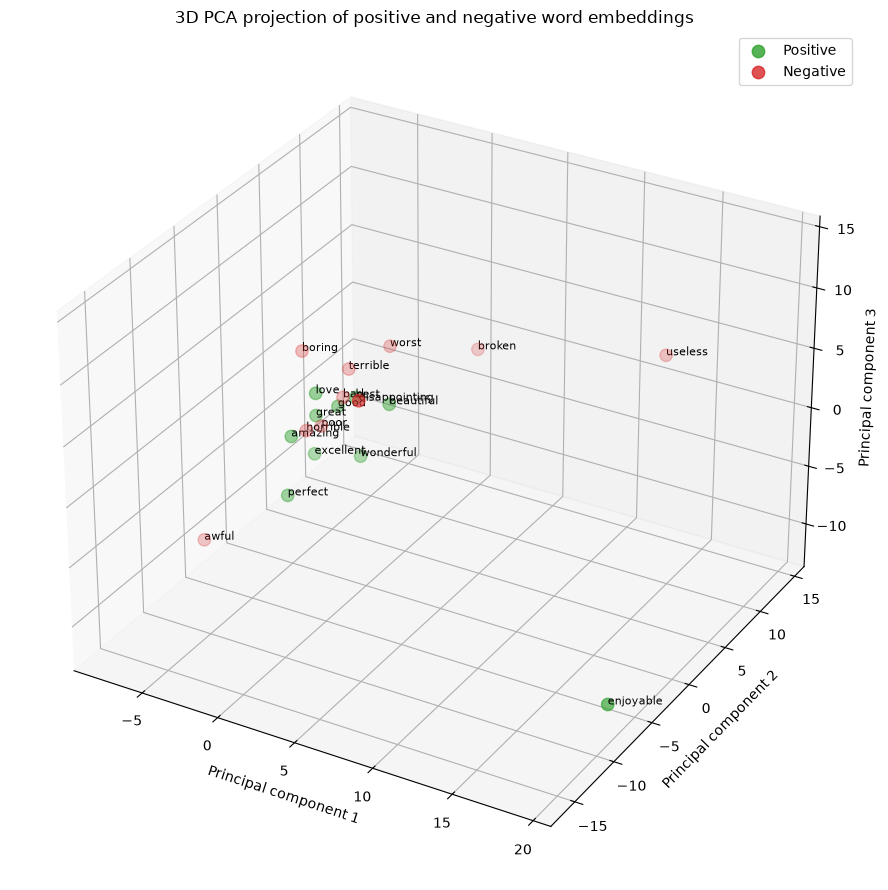

In [52]:
import matplotlib.pyplot as plt

positive_candidates = [
    "excellent", "wonderful", "amazing", "great", "perfect",
    "good", "love", "best", "beautiful", "enjoyable",
]
negative_candidates = [
    "terrible", "horrible", "awful", "bad", "worst",
    "poor", "disappointing", "boring", "useless", "broken",
]

# Keep only words that survived preprocessing and are in the vocabulary.
positive_words = [word for word in positive_candidates if word in token_to_id]
negative_words = [word for word in negative_candidates if word in token_to_id]
selected_words = positive_words + negative_words
selected_ids = torch.tensor(
    [token_to_id[word] for word in selected_words], dtype=torch.long
)

with torch.no_grad():
    selected_vectors = model.embedding(selected_ids.to(device)).cpu()

# Project the learned embeddings onto three PCA dimensions.
centered_vectors = selected_vectors - selected_vectors.mean(dim=0)
_, _, principal_axes = torch.linalg.svd(centered_vectors, full_matrices=False)
coordinates = centered_vectors @ principal_axes[:3].T
positive_end = len(positive_words)
positive_coordinates = coordinates[:positive_end]
negative_coordinates = coordinates[positive_end:]

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(
    positive_coordinates[:, 0], positive_coordinates[:, 1], positive_coordinates[:, 2],
    color="tab:green", s=80, alpha=0.8, label="Positive",
)
ax.scatter(
    negative_coordinates[:, 0], negative_coordinates[:, 1], negative_coordinates[:, 2],
    color="tab:red", s=80, alpha=0.8, label="Negative",
)

for word, (x, y, z) in zip(selected_words, coordinates.tolist()):
    ax.text(x, y, z, word, fontsize=8)

ax.set_title("3D PCA projection of positive and negative word embeddings")
ax.set_xlabel("Principal component 1")
ax.set_ylabel("Principal component 2")
ax.set_zlabel("Principal component 3")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()